In [4]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")

import numpy as np
import pandas as pd

import src.features as F
import src.split as S
import src.metrics as M
import src.modeling as MD

df = pd.read_parquet("../data/processed/clean.parquet")
feats = F.build_features(df)
train, val, _ = S.time_split(feats)          # test stays out of error analysis

# train-only Huber model, the same one that scored 9.63 on validation
train_m, (val_m,) = MD.add_store_features(train, [val])
cats = MD.fit_categories(train)
X_tr, X_val = MD.to_lgbm_frame(train_m, cats), MD.to_lgbm_frame(val_m, cats)
model = MD.fit_lgbm(X_tr, train["duration"], X_val, val["duration"],
                    objective="huber", alpha=600)

val_a = val_m.copy()                          # features + store encoding
val_a["pred"] = model.predict(X_val)
val_a["err"] = val_a["pred"] - val_a["duration"]           # > 0 means over-prediction
val_a["abs_err_min"] = val_a["err"].abs() / 60
print("overall val MAE:", round(val_a["abs_err_min"].mean(), 3), "(expect about 9.63)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
overall val MAE: 9.634 (expect about 9.63)


In [5]:
def segment_report(frame, by, min_rows=300):
    g = frame.groupby(by, observed=True)
    out = pd.DataFrame({
        "rows": g.size(),
        "share_%": (g.size() / len(frame) * 100).round(1),
        "mae_min": g["abs_err_min"].mean().round(2),
        "bias_min": (g["err"].mean() / 60).round(2),
        "mean_actual_min": (g["duration"].mean() / 60).round(1),
        "err_share_%": (g["abs_err_min"].sum() / frame["abs_err_min"].sum() * 100).round(1),
    })
    return out[out["rows"] >= min_rows]

val_a["supply_bin"] = pd.cut(val_a["available_dashers"], [-0.1, 0, 5, 20, np.inf],
                             labels=["0", "1-5", "6-20", "21+"])
val_a["supply_bin"] = val_a["supply_bin"].cat.add_categories("missing").fillna("missing")
val_a["size_bin"] = pd.cut(val_a["total_items"], [0, 2, 4, 8, np.inf],
                           labels=["1-2", "3-4", "5-8", "9+"])
store_n = (val_a["store_share"] * len(train)).round()      # store's order count in train
val_a["store_orders"] = pd.cut(store_n, [-0.5, 0.5, 20, 100, np.inf],
                               labels=["unseen", "1-20", "21-100", "101+"])

for col in ["hour", "day_of_week", "market_id", "order_protocol",
            "supply_bin", "size_bin", "store_orders"]:
    print(f"\n=== by {col} ===")
    display(segment_report(val_a, col))

print("\n=== top 10 store categories by share of total error ===")
display(segment_report(val_a, "store_primary_category")
        .sort_values("err_share_%", ascending=False).head(10))


=== by hour ===


,rows,share_%,mae_min,bias_min,mean_actual_min,err_share_%
hour,,,,,,
9,428,1.5,9.93,-0.55,41.4,1.5
10,675,2.3,9.25,-1.25,40.2,2.3
11,2156,7.5,10.52,-4.09,48.5,8.2
12,2362,8.2,9.67,-2.94,45.7,8.2
13,1492,5.2,8.97,-0.79,39.8,4.8
14,1090,3.8,8.95,-1.82,40.0,3.5
15,998,3.5,10.12,-3.44,43.8,3.6
16,1682,5.8,9.68,-2.98,45.0,5.9
17,3949,13.7,9.49,-1.71,48.8,13.5



=== by day_of_week ===


,rows,share_%,mae_min,bias_min,mean_actual_min,err_share_%
day_of_week,,,,,,
1,6211,21.6,9.02,-1.31,44.3,20.2
2,6711,23.3,9.61,-0.54,44.7,23.3
3,7245,25.2,9.21,-3.18,46.2,24.1
4,8611,29.9,10.45,-3.44,52.0,32.4



=== by market_id ===


...

,rows,share_%,mae_min,bias_min,mean_actual_min,err_share_%
size_bin,,,,,,
1-2,14431,50.1,9.55,-2.30,45.1,49.7
3-4,8996,31.3,9.74,-2.27,48.0,31.6
5-8,4403,15.3,9.58,-1.97,50.7,15.2
9+,948,3.3,10.16,-2.36,55.4,3.5



=== by store_orders ===


,rows,share_%,mae_min,bias_min,mean_actual_min,err_share_%
store_orders,,,,,,
unseen,384,1.3,11.37,-3.43,51.0,1.6
1-20,6742,23.4,10.84,-2.48,47.8,26.4
21-100,12884,44.8,9.53,-2.15,46.7,44.3
101+,8768,30.5,8.79,-2.14,47.2,27.8



=== top 10 store categories by share of total error ===


,rows,share_%,mae_min,bias_min,mean_actual_min,err_share_%
store_primary_category,,,,,,
american,2861,9.9,9.96,-2.87,47.2,10.3
pizza,2494,8.7,9.66,-2.39,50.6,8.7
mexican,2534,8.8,9.07,-2.13,44.0,8.3
burger,1578,5.5,9.28,-2.17,46.8,5.3
sandwich,1577,5.5,9.40,-2.23,45.1,5.3
japanese,1387,4.8,10.23,-2.50,51.1,5.1
chinese,1388,4.8,9.88,-2.55,47.9,4.9
dessert,1241,4.3,9.23,-1.80,46.7,4.1
fast,1112,3.9,10.18,-1.59,42.8,4.1


### Observations: segment errors (validation)

**1. No single segment dominates.** MAE sits between 8 and 11.4 min in nearly every segment, which points to noise the features cannot explain rather than a fixable blind spot.

**2. Scarce supply is the weakest regime.** With zero available dashers MAE is 11.15 min (26.8% of rows, 31.0% of total error); with 21+ available it is 8.11. When supply is exhausted, waits are volatile and the model cannot see why.

**3. Store history matters.** MAE falls with a store's training order count: unseen 11.37, 1-20 orders 10.84, 21-100 orders 9.53. Low-history stores are 23% of rows but 26% of error. Store-specific signals beyond a smoothed mean are the clearest next lever.

**4. Order size is not an error driver.** MAE is flat (9.5-10.2) from 1-2 items to 9+ items.

**5. Hours are handled well, except the 11:00 lunch bump,** where the model under-predicts by 4.1 min (actual mean 48.5 min vs 40.2 at 10:00 and 45.7 at 12:00).

**6. Bias is negative in every segment (about -2 min),** consistent with a median-targeting loss on a right-skewed target.

worst 1% of orders -> 6.8% of total absolute error (their MAE: 65.4 min)
worst 5% of orders -> 20.5% of total absolute error (their MAE: 39.5 min)
worst 10% of orders -> 32.3% of total absolute error (their MAE: 31.2 min)
worst 25% of orders -> 56.9% of total absolute error (their MAE: 21.9 min)


count    28778.00
mean         9.63
std          9.75
min          0.00
50%          7.21
75%         12.77
90%         20.06
95%         26.31
99%         46.44
max        129.29
Name: abs_err_min, dtype: float64


worst 5%: 96% are under-predictions | mean actual 86 min | mean predicted 48 min


,pred_min,actual_median_min,actual_mean_min
pred_bin,,,
"(1198.501, 1964.777]",29.6,29.7,31.5
"(1964.777, 2172.843]",34.6,34.8,36.7
"(2172.843, 2336.319]",37.6,38.0,40.0
"(2336.319, 2485.894]",40.2,40.2,42.7
"(2485.894, 2633.769]",42.6,43.2,45.4
"(2633.769, 2792.447]",45.2,45.2,47.3
"(2792.447, 2976.137]",48.0,47.8,50.1
"(2976.137, 3198.642]",51.4,51.4,53.6
"(3198.642, 3521.128]",55.8,55.4,57.9


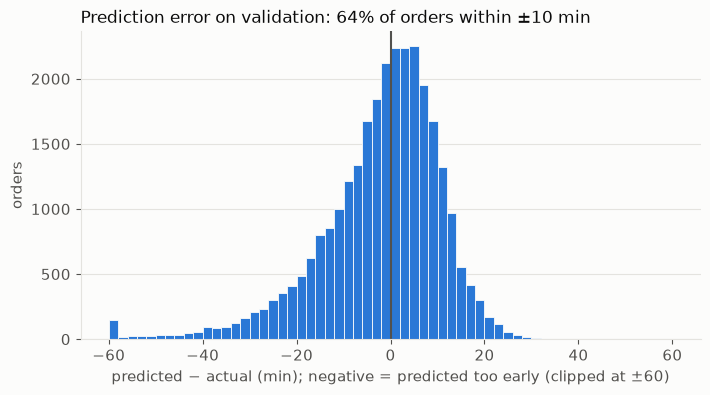

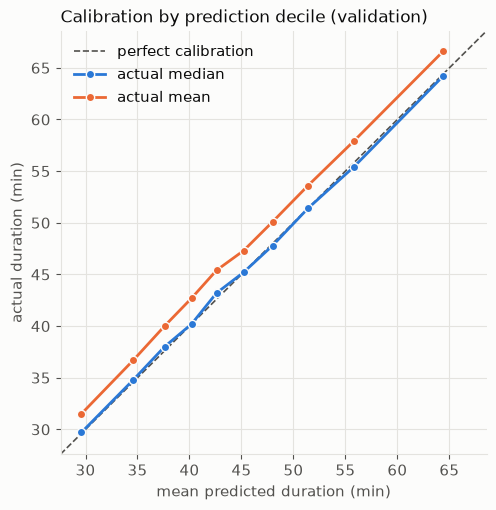

In [6]:
import matplotlib.pyplot as plt

# --- tail of the error distribution
abs_e = val_a["abs_err_min"].sort_values(ascending=False)
for q in [0.01, 0.05, 0.10, 0.25]:
    top = abs_e.head(int(len(abs_e) * q))
    print(f"worst {q:.0%} of orders -> {top.sum() / abs_e.sum():.1%} of total absolute error "
          f"(their MAE: {top.mean():.1f} min)")
display(val_a["abs_err_min"].describe(percentiles=[.5, .75, .9, .95, .99]).round(2))

worst = val_a.nlargest(int(len(val_a) * 0.05), "abs_err_min")
print(f"\nworst 5%: {(worst['err'] < 0).mean():.0%} are under-predictions | "
      f"mean actual {worst['duration'].mean() / 60:.0f} min | "
      f"mean predicted {worst['pred'].mean() / 60:.0f} min")

# --- calibration by prediction decile
val_a["pred_bin"] = pd.qcut(val_a["pred"], 10, duplicates="drop")
g = val_a.groupby("pred_bin", observed=True)
cal = pd.DataFrame({"pred_min": g["pred"].mean() / 60,
                    "actual_median_min": g["duration"].median() / 60,
                    "actual_mean_min": g["duration"].mean() / 60}).round(1)
display(cal)

# --- figures (single validated blue, quiet grid, thin marks)
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "regular",
    "axes.titlelocation": "left",
})

# 1. error distribution
err_min = (val_a["err"] / 60).clip(-60, 60)
within = (val_a["abs_err_min"] <= 10).mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(err_min, bins=np.arange(-60, 61, 2), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.axvline(0, color=MUTED, linewidth=1.5)
ax.set_title(f"Prediction error on validation: {within:.0%} of orders within ±10 min")
ax.set_xlabel("predicted − actual (min); negative = predicted too early (clipped at ±60)")
ax.set_ylabel("orders")
ax.grid(axis="x", visible=False)
fig.savefig("../reports/figures/error_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# 2. calibration (two series + perfect-calibration reference)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = [cal[["pred_min", "actual_median_min", "actual_mean_min"]].min().min() - 2,
       cal[["pred_min", "actual_median_min", "actual_mean_min"]].max().max() + 2]
ax.plot(lim, lim, color=MUTED, linewidth=1.2, linestyle="--", label="perfect calibration")
ax.plot(cal["pred_min"], cal["actual_median_min"], color=BLUE, linewidth=2,
        marker="o", markersize=6, markeredgecolor=SURFACE, label="actual median")
ax.plot(cal["pred_min"], cal["actual_mean_min"], color=ORANGE, linewidth=2,
        marker="o", markersize=6, markeredgecolor=SURFACE, label="actual mean")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title("Calibration by prediction decile (validation)")
ax.set_xlabel("mean predicted duration (min)")
ax.set_ylabel("actual duration (min)")
ax.legend(frameon=False, loc="upper left")
fig.savefig("../reports/figures/calibration.png", dpi=160, bbox_inches="tight")
plt.show()

market_id,1,2,3,4,5,6,unknown
hour,,,,,,,
6,0.1,NaN,0.1,NaN,NaN,NaN,NaN
7,0.5,0.1,0.7,0.1,0.1,0.1,NaN
8,1.2,1.2,1.3,0.9,0.9,0.7,0.7
9,1.9,1.8,2.2,1.4,1.5,1.6,2.5
10,2.7,2.7,2.9,2.3,2.5,2.6,3.1
11,6.4,6.9,6.6,7.4,6.4,6.1,7.8
12,8.0,7.8,8.0,8.0,8.0,6.7,7.2
13,5.9,6.0,6.1,5.7,6.2,5.4,4.4
14,4.7,4.6,4.8,4.0,5.0,4.5,4.0


peak hour (Pacific) by market:
market_id
1          18
2          18
3          18
4          18
5          18
6          18
unknown    18
additivity check, max abs gap: 4.83e-13 min


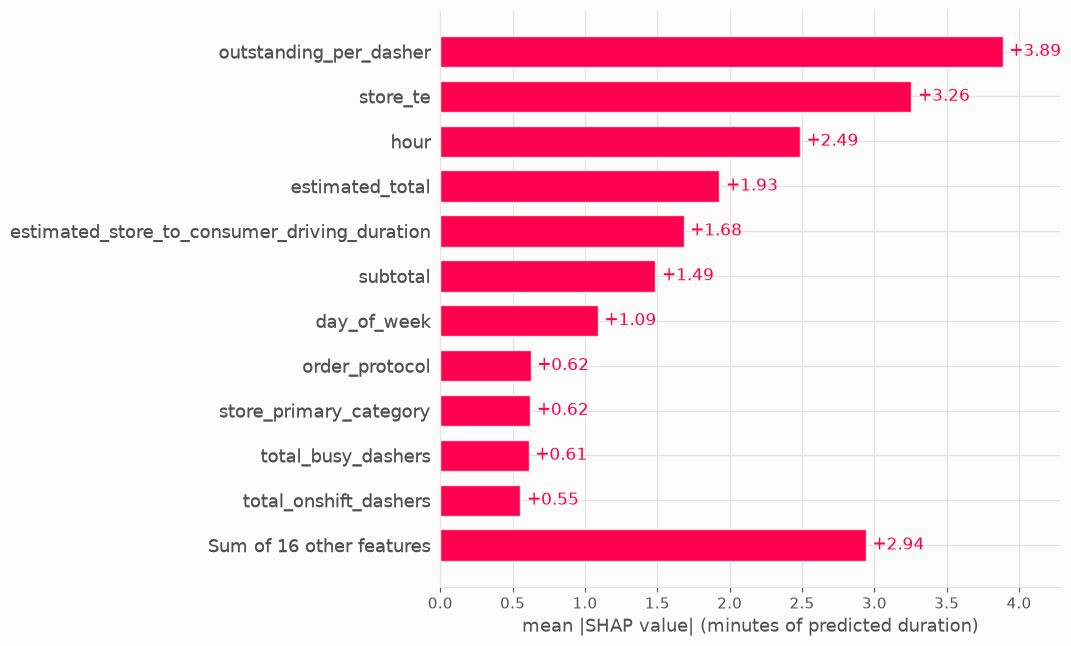

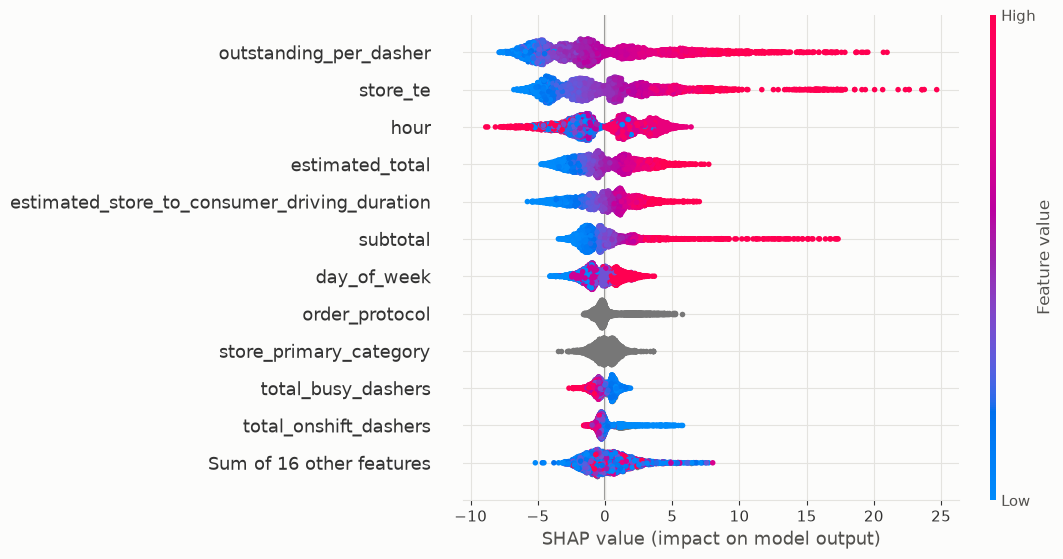

dependence plots for: ['outstanding_per_dasher', 'store_te', 'hour', 'estimated_total']


c:\Users\arpan\delivery-duration-prediction\.venv\Lib\site-packages\shap\plots\_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


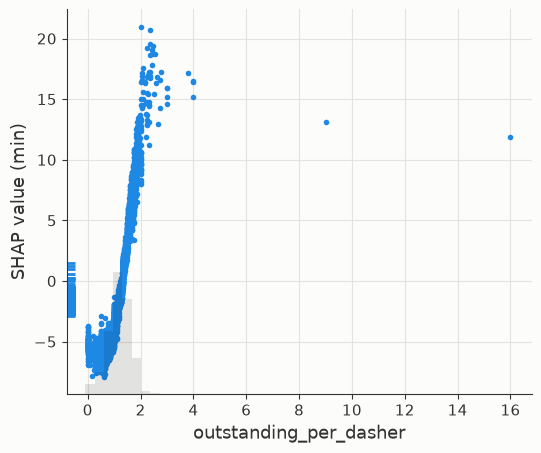

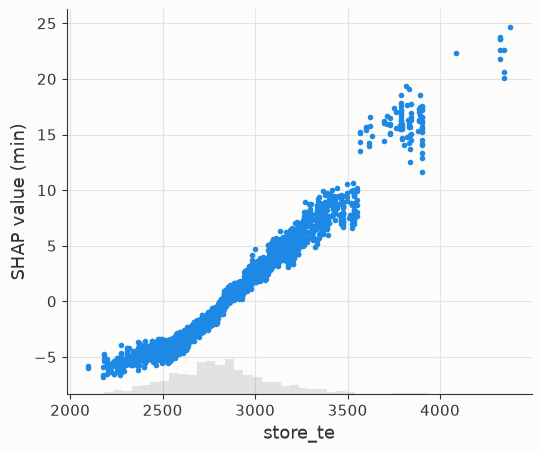

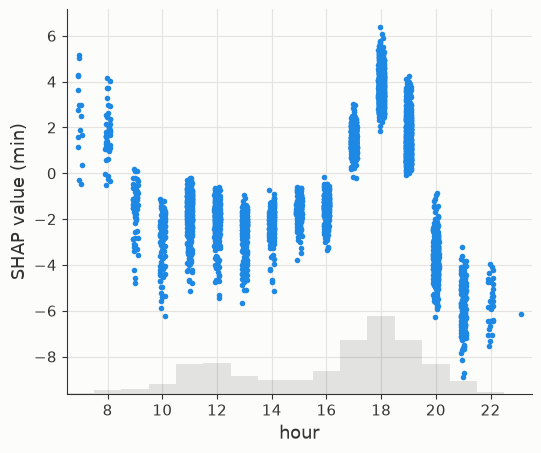

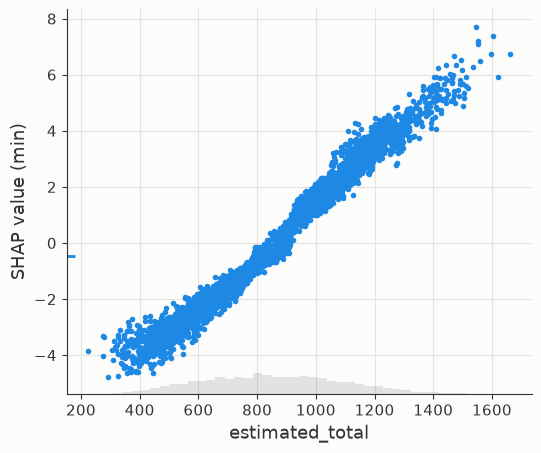

worst under-prediction: actual 176 min, predicted 47 min


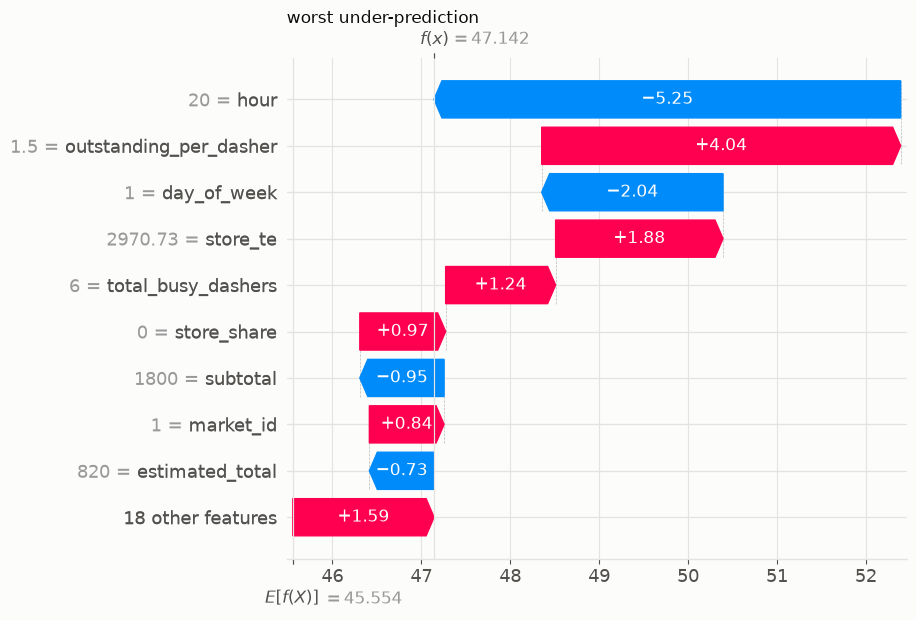

near-perfect prediction: actual 53 min, predicted 53 min


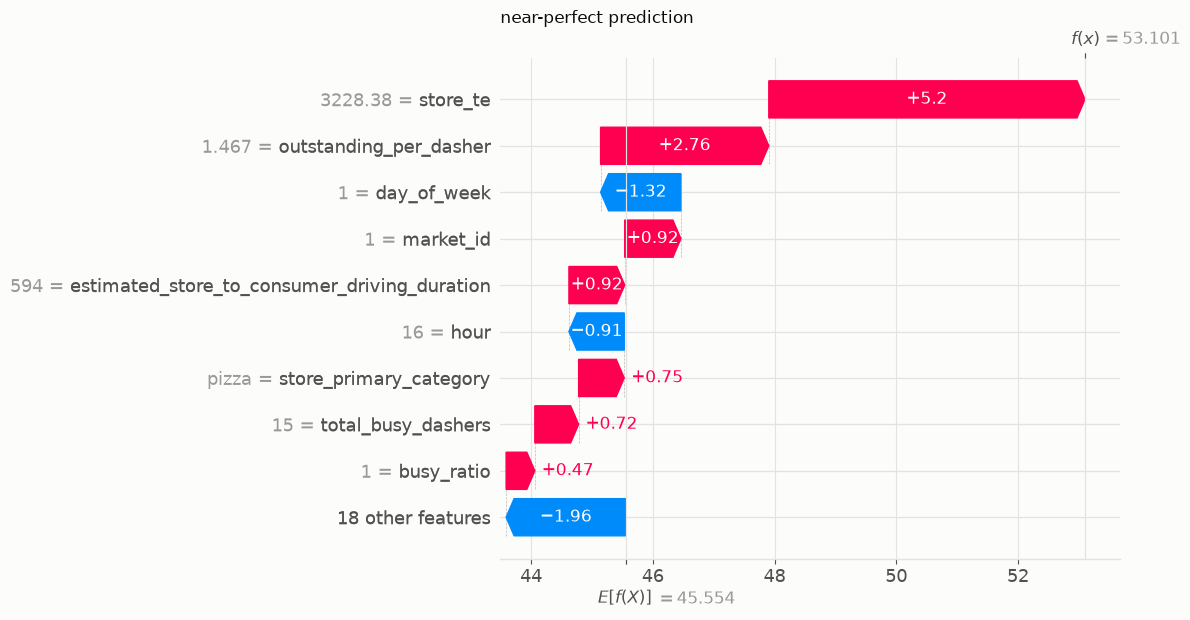

In [7]:
# (a) Do markets share one daily rhythm? (order counts only, train rows)
prof = train.groupby(["market_id", "hour"]).size().unstack(0)
prof = (prof / prof.sum() * 100).round(1)
display(prof)
print("peak hour (Pacific) by market:")
print(prof.idxmax().to_string())

# (b) SHAP on a 5,000-row validation sample
import shap
import matplotlib.pyplot as plt

idx = np.random.default_rng(0).choice(len(X_val), size=5000, replace=False)
sample, sample_a = X_val.iloc[idx], val_a.iloc[idx]

explainer = shap.TreeExplainer(model)
sv = explainer(sample)                                           # seconds
sv_min = shap.Explanation(values=sv.values / 60, base_values=sv.base_values / 60,
                          data=sv.data, feature_names=sv.feature_names)
gap = np.abs(sv_min.values.sum(1) + sv_min.base_values - model.predict(sample) / 60).max()
print(f"additivity check, max abs gap: {gap:.2e} min")

# global importance and direction
shap.plots.bar(sv_min, max_display=12, show=False)
plt.xlabel("mean |SHAP value| (minutes of predicted duration)")
plt.savefig("../reports/figures/shap_importance.png", dpi=160, bbox_inches="tight")
plt.show()

shap.plots.beeswarm(sv_min, max_display=12, show=False)
plt.savefig("../reports/figures/shap_beeswarm.png", dpi=160, bbox_inches="tight")
plt.show()

# dependence plots for the top numeric features
numeric_top = [sv_min.feature_names[i]
               for i in np.abs(sv_min.values).mean(0).argsort()[::-1]
               if sv_min.feature_names[i] not in MD.LGBM_CATEGORICAL][:4]
print("dependence plots for:", numeric_top)
for feat in numeric_top:
    shap.plots.scatter(sv_min[:, feat], show=False)
    plt.ylabel("SHAP value (min)")
    plt.savefig(f"../reports/figures/shap_dependence_{feat}.png", dpi=160, bbox_inches="tight")
    plt.show()

# two single-order explanations
err = sample_a["err"].to_numpy()
cases = {"worst under-prediction": int(err.argmin()),
         "near-perfect prediction": int(np.abs(err).argmin())}
for label, i in cases.items():
    print(f"{label}: actual {sample_a['duration'].iloc[i] / 60:.0f} min, "
          f"predicted {sample_a['pred'].iloc[i] / 60:.0f} min")
    shap.plots.waterfall(sv_min[i], max_display=10, show=False)
    plt.title(label)
    plt.savefig(f"../reports/figures/shap_waterfall_{label.split()[0]}.png",
                dpi=160, bbox_inches="tight")
    plt.show()